# Transforms and layout

Every shape carries one transform. Copies of a petal are rotated about a shared pivot, flipped and placed,
then a second drawing lays shapes out with the named points of their bounds and `align`.

Run it as ``python transforms_and_layout.py`` or open ``transforms_and_layout.ipynb`` to see each step.

In [1]:
import svgwriter as svg

## Transforms

Every shape carries one transform. `rotate(angle, about=pivot)` edits it, so copies of a petal
turned about the centre make a ring.

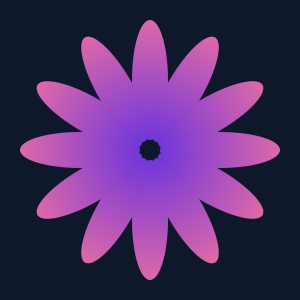

In [2]:
SIZE = 300
CENTER = (SIZE / 2, SIZE / 2)
PETALS = 12

doc = svg.Document(SIZE, SIZE)
doc.rect(0, 0, SIZE, SIZE, fill="#0f172a")

petal = svg.ellipse(SIZE / 2, SIZE / 2 - 70, 18, 60, fill=svg.LinearGradient.vertical("#f472b6", "#7c3aed"))
with doc.group(opacity=0.9):
    for i in range(PETALS):
        doc.add(petal @ 0).rotate(360 * i / PETALS, about=CENTER)
doc

Subtracting one shape from another (`-`) gives a path with a cut-out: a disc minus a star.

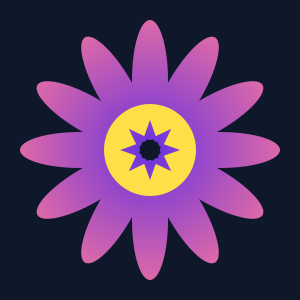

In [3]:
core = svg.circle(*CENTER, 46) - svg.paths.star(*CENTER, 30, points=8)
doc += core.update(fill="#fde047")
doc

`place(x, y)` moves a shape's origin, which suits shapes built around (0, 0).

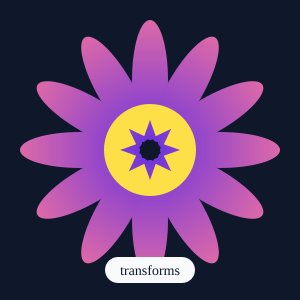

In [4]:
badge = svg.rect.from_center((0, 0), (90, 26), rx=13, fill="#f8fafc")
doc += badge.place(SIZE / 2, SIZE - 30)
doc.text("transforms", x=SIZE / 2, y=SIZE - 25, font_size=14, text_anchor="middle", fill="#0f172a")
doc

`flip_x` and `flip_y` mirror a clone about a point: one arrow becomes four corners.

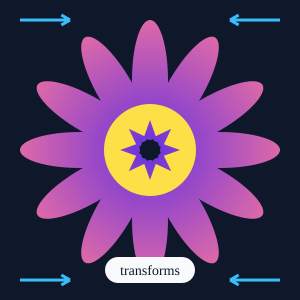

In [5]:
corner = svg.paths.arrow(20, 20, 70, 20, head=10, stroke="#38bdf8", stroke_width=3)
doc += [corner, corner.clone().flip_x(about=CENTER), corner.clone().flip_y(about=CENTER),
        corner.clone().flip_x(about=CENTER).flip_y(about=CENTER)]
doc

`clip` intersects a shape with another: a square clipped by a circle is a round frame.

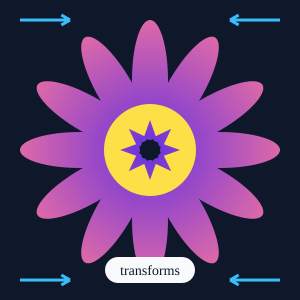

In [6]:
window = svg.rect(0, 0, SIZE, SIZE).clip(svg.circle(*CENTER, SIZE / 2 - 4))
window.update(fill="none", stroke="#334155", stroke_width=8)
doc += window
doc

## Named points and align

Every element knows its `bounds()`, a box with named points: `center`, the corners (`top_left`,
`bottom_right`, ...) and the edge middles (`top`, `left`, ...). Dots mark them on a card.

Point(x=150.0, y=80.0) Point(x=60.0, y=40.0) Point(x=240.0, y=120.0)


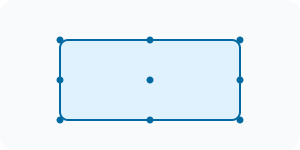

In [7]:
layout = svg.Document(300, 150)
layout.rect(0, 0, 300, 150, rx=14, fill="#f8fafc")
card = layout.rect(60, 40, 180, 80, rx=8, fill="#e0f2fe", stroke="#0369a1", stroke_width=2)
box = card.bounds()
print(box.center, box.top_left, box.bottom_right)
for name in ("top_left", "top", "top_right", "left", "center", "right", "bottom_left", "bottom", "bottom_right"):
    point = box.point(name)
    layout.circle(point.x, point.y, 3.5, fill="#0369a1")
layout

`align(target, at, to=...)` moves an element so its point `at` meets the point `to` of the target,
and `offset` adds a gap. `place(x, y, at=...)` does the same for a plain coordinate.

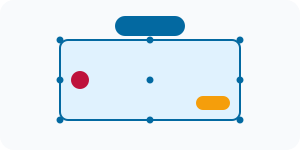

In [8]:
tab = svg.rect(0, 0, 70, 20, rx=10, fill="#0369a1")
layout += tab.align(card, "bottom", to="top", offset=(0, -4))
corner = svg.rect(0, 0, 34, 14, rx=7, fill="#f59e0b")
layout += corner.align(card, "bottom_right", offset=(-10, -10))
stamp = svg.circle(0, 0, 9, fill="#be123c").place(box.left + 20, box.center.y, at="center")
layout += stamp
layout

Save SVG and a 2x PNG.

In [9]:
doc.save("02_transforms_and_layout.svg")
doc.save("02_transforms_and_layout.png", scale=2)
layout.save("02_layout.svg")